<h1 style="text-align: center"> City-cycle Fuel Consumption Analysis & Prediction </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

<div>
    <a href="../notebook/__1_business_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white"> Previous </a>
    <a href="../notebook/__2_data_analysis.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>

## Section 1.1 | Data Understanding

In [1]:
# import required library

# data ETL
from ucimlrepo import fetch_ucirepo
import pandas as pd

# data cleaning
import matplotlib.pyplot as plt
import seaborn as sns
from pyampute.exploration.mcar_statistical_tests import MCARTest

### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: cars](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Dataset Characteristics | Tabular, Multivariate |
| Associated Tasks | Regression |
| Feature Type | Real, Integer |
| # Instances | 398 |
| # Features | 7 |

</div>

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes.

> This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by Quinlan (1993) in predicting the attribute `mpg` (as stated above), 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 2 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 3 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 4 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 5 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 6 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 7 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 8 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |

</div>

### Data ETL

In [2]:
# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# raw data (as Pandas dataframes)
features = auto_mpg.data.features
target = auto_mpg.data.targets
data_raw = pd.concat(
    objs=[features, target],
    axis=1
)

# show data samples
data_raw.head(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


**Observations:**
* Data succesfully **extracted** from the input source, **transformed** to the appropriate format, and **loaded** into the variable instance.
* Ditampilkan 5 baris data pertama dari dataset sebagai contoh hasil dari tahapan ETL:
    * Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
    * Sedangkan kolom adalah variabel atau *feature* yang mewakili keragaman dari each samples.
        * Khusus untuk kolom terakhir merupakan *target variable*, which is the variable that corresponds to the input data (features). 
        * Variabel ini lebih berperan dalam statistical analysis ataupun machine learning tasks, yang akan dilakukan pada bagian-bagian berikutnya dalam project ini.

## Section 1.2 | Data Inspection

### Initial Data Inspection

In [ ]:
def inspect_data(data):
    """Function to inspect dataset characteristics.

    Args:
        data (DataFrame): dataset to inspect.

    Returns:
        DataFrame: DataFrame containing dataset descriptions and anomalies.
    """    
    data_description = pd.DataFrame(
        data={
            'Row/Instance': data.shape[0],
            'Column/Variable': data.shape[1],
            'Continuous Variable': len(data.select_dtypes(include='float64').columns),
            'Integer Variable': len(data.select_dtypes(include='int64').columns),
            'Categorical Variable': len(data.select_dtypes(include='object').columns)
        },
        index=['Value']
    ).transpose()
    
    data_inspection = pd.DataFrame(data={
        'Dtype': data.dtypes,
        'Duplicated': data.duplicated().sum(),
        'Missing': data.isna().sum(),
        'Sample': [data[column].unique() for column in data.columns],
        'Min': [data[column].min() for column in data.columns],
        'Max': [data[column].max() for column in data.columns]
    }).rename_axis(index='Variable')
    
    return data_description, data_inspection

In [4]:
# perform inspection on raw dataset
data_description, data_inspection = inspect_data(data=data_raw)

print('Data Description:')
display(data_description)
print('Data Inspection:')
display(data_inspection)

Data Description:


,Value
Row/Instance,398
Column/Variable,8
Continuous Variable,4
Integer Variable,4
Categorical Variable,0


Data Inspection:


,Dtype,Duplicated,Missing,Sample,Min,Max
Variable,,,,,,
displacement,float64,0,0,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0
cylinders,int64,0,0,"[8, 4, 6, 3, 5]",3.0,8.0
horsepower,float64,0,6,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0
weight,int64,0,0,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0
acceleration,float64,0,0,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8
model_year,int64,0,0,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0
origin,int64,0,0,"[1, 3, 2]",1.0,3.0
mpg,float64,0,0,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6


**Observations:**
* Terdapat `398` baris dalam dataset yang ditunjukkan dalam `Data Description`
    * Baik yang berasal dari feature variable `X` maupun target variable `y`.
    * Berdasarkan penjelasan pada `Section 1: Data Context`:
        * Pengambilan baris data ini diasumsikan menggunakan [simple random sampling](https://en.wikipedia.org/wiki/Sampling_(statistics)#Simple_random_sampling), yakni 
        * Sampel dari populasi dipilih acak dalam [sampling frame](https://en.wikipedia.org/wiki/Sampling_frame) kendaraan dengan `model_year: 70-82` dan `origin: American, European, Japanese`.
* Jumlah `8` kolom sesuai dengan yang telah dipaparkan dalam `Section 1: Data Context`
    * Terdiri dari 7 feature variables dan 1 target variable.
    * Nama dari kolom-kolom tersebut tertera dalam indeks `Variable` pada `Data Inspection`.
* Kolom `Dtype` menunjukkan jenis tipe data yang ada dalam dataset, yakni terdiri dari `float` dan `int`:
    * Jumlah dari kedua tipe data tersebut ditunjukkan dalam `Data Description`: `4` kolom `float` dan `4` kolom `int`.
    * Tipe data tersebut sudah sesuai dengan random `Sample` yang ditunjukkan pada tiap variabel.
        * Semisal `displacement` berisikan bilangan desimal `307.0, 350.0, 318.0, ...`, dan 
        * `cylinders` berisikan bilangan bulat `8, 4, 6, 3, 5`.
    * Namun domain knowledge mengindikasikan bahwa beberapa variabel tersebut sebenarnya memiliki tipe data yang tidak sesuai:
        * `cylinders & model_year` dengan deskripsi data jumlah silinder mesin dan tahun model dari city-cycle sewajarnya bertipe [ordinal](https://en.wikipedia.org/wiki/Ordinal_data), serta
        * `origin` dengan deskripsi origin of the car seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Proses data audit meliputi deteksi terhadap `Duplicated` & `Missing` data, variable magnitude, dan their numerical values:
    * Tidak ada duplicated data yang terdeteksi, sebagaimana ditunjukkan pada nilai kolom `Duplicated` untuk seluruh variabel bernilai `0`
    * Terdeteksi adanya missing data pada salah satu variabel:
        * Sebagaimana ditunjukkan pada nilai kolom `Missing` untuk variabel `horsepower` bernilai `6`.
        * Missing data [reduces](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) the representativeness of the sample and can therefore distort inferences about the population.
    * Terdeteksi adanya perbedaan rentang nilai atau magnitude antar variabel numerikal:
        * Mulai dari rentang satuan `1, 3, 2` pada variabel `origin` hingga ribuan `3504, 3693, 3436, ...` pada variabel `weight`.
        * Keragaman nilai ini tidak memberikan dampak yang signifikan untuk data analysis:
            * E.g. skala pada tiap visualisasi data dapat diatur sesuai rentang nilai from the data; but 
            * May pose several problems in machine learning models (*will be explained in further section that deals with data modeling*).
    * Tidak ada invalid data issue yang terdeteksi:
        * Rentang nilai yang ditunjukkan dari kolom `Min` dan ` Max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
        * Ambil contoh pada kolom `acceleration`, masih diwajarkan jika suatu car membutuhkan waktu `8` hingga `24.8` detik to accelerate from 0 to 60 mph.

<center>

| Anomaly | Insight | Action |
| --- | --- | --- |
| *Data Type* | *Data type issue detected* | *Processed in `Section 1: Data Cleaning`* |
| Duplicated Data | No duplicated data detected | No further action required |
| *Missing Data* | *Missing data detected* | *Analyzed further in `Section 1: Data Cleaning`* |
| *Variable Magnitude* | *Variable magnitude issue detected* | *Analyzed further in `Section 3: Data Preprocessing`* |
| Invalid Data | No invalid data issue detected | No further action required |

</center>

### Data Cleaning


In [5]:
# copy raw data to new instance
data = data_raw.copy()

*Copying into new dataframe*:
1. *To avoid reflecting modifications to the original dataset, and*
2. *To avoid [chained indexing](https://pandas.pydata.org/docs/user_guide/indexing.html#indexing-view-versus-copy).*

#### Data Type

In [ ]:
def convert_categorical_variable(categorical_variables, data):
    """Function to convert categorical variables in dataset.

    Args:
        categorical_variable (List): List containing names of categorical variables to convert.
        data (DataFrame): dataset containing names of categorical variables.

    Returns:
        DataFrame: cleaned dataset with converted variables.
    """    
    for variable in categorical_variables:
        data[variable] = data[variable].astype(dtype='object')

    return data

In [7]:
# perform variables conversion
data = convert_categorical_variable(
    categorical_variables=['cylinders', 'model_year', 'origin'],
    data=data
)

**Observations:**
* Variabel yang seharusnya memiliki tipe data kategorikal berhasil diubah ke tipe yang sesuai menggunakan fungsi `astype`.
* Hasil konversi ini akan ditunjukkan pada bagian `Final Data Audit` berikutnya.

#### Missing Data

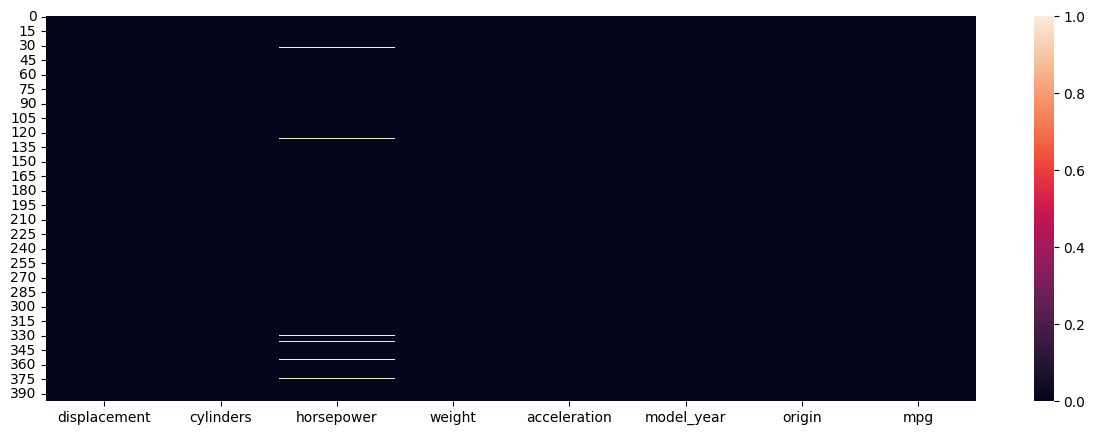

In [8]:
# plot heatmap consisting of missing data
plt.figure(figsize=(15, 5))

axes = sns.heatmap(
    data=data.isna()
)

# rotate x-axis labels for easier interpretation
axes.set_xticklabels(
    labels=axes.get_xmajorticklabels(),
    rotation=0
)

plt.show()

**Observations:**
* Heatmap di atas menunjukkan:
    * Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan
    * Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam dataset.
* Dari visualisasi ini, dapat diinterpretasikan bahwa:
    * Missing data terletak pada lokasi yang acak pada `horsepower`;
    * Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [9]:
# slice missing data in dataset
data[data['horsepower'].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


**Observations:**
* DataFrame di atas menunjukkan:
    * Sampel dengan missing data pada `horsepower`,
    * Nilai pada variabel lain dalam dataset dengan missing data tersebut, dan
    * Indeks dari missing data dalam dataset.
* A priori, dapat disimpulkan bahwa:
    * Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
    * Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [ ]:
# perform Little's MCAR test
mcar_test = MCARTest(method='little')
mcar_test_pvalue = mcar_test.little_mcar_test(X=data)

def mcar_test_evaluation(mcar_test_decision):
    """Function to evaluate Little's MCAR test result.

    Args:
        mcar_test_decision (string): string object describing decision towards the test result.

    Returns:
        DataFrame: display DataFrame containing the test p-Value and decision.
    """    
    df_mcar_test = pd.DataFrame(
        data=[mcar_test_pvalue,
              mcar_test_decision],
        index=['p-Value',
               'Decision'],
        columns=['Value']
    )
    return display(df_mcar_test)

*Little's MCAR Test (1988) adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire dataset; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

In [ ]:
# evaluate Little's MCAR test p-Value
significance_level = 0.05
if mcar_test_pvalue <= significance_level:
    mcar_test_evaluation(mcar_test_decision='Accept Ha')
else:
    mcar_test_evaluation(mcar_test_decision='Accept H0')

,Value
p-Value,0.313475
Decision,Accept H0


**Observations:**

* Hasil observasi secara visual, tabular, serta uji statistik di atas memberikan inferensi bahwa missing data pada dataset adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the dataset. In other words, those missing data points are a random subset of the data.
* There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [ ]:
# drop missing values from dataset
data_cleaned = data.dropna()

### Final Data Audit

In [13]:
# inspection results on raw dataset
data_description, data_inspection = inspect_data(data=data_raw)

print('Data Description:')
display(data_description)
print('Data Inspection:')
display(data_inspection)

Data Description:


,Value
Row/Instance,398
Column/Variable,8
Continuous Variable,4
Integer Variable,4
Categorical Variable,0


Data Inspection:


,Dtype,Duplicated,Missing,Sample,Min,Max
Variable,,,,,,
displacement,float64,0,0,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0
cylinders,int64,0,0,"[8, 4, 6, 3, 5]",3.0,8.0
horsepower,float64,0,6,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0
weight,int64,0,0,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0
acceleration,float64,0,0,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8
model_year,int64,0,0,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0
origin,int64,0,0,"[1, 3, 2]",1.0,3.0
mpg,float64,0,0,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6


In [14]:
# inspection results on cleaned dataset
data_description, data_inspection = inspect_data(data=data_cleaned)

print('Data Description:')
display(data_description)
print('Data Inspection:')
display(data_inspection)

Data Description:


,Value
Row/Instance,392
Column/Variable,8
Continuous Variable,4
Integer Variable,1
Categorical Variable,3


Data Inspection:


,Dtype,Duplicated,Missing,Sample,Min,Max
Variable,,,,,,
displacement,float64,0,0,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0
cylinders,object,0,0,"[8, 4, 6, 3, 5]",3.0,8.0
horsepower,float64,0,0,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0
weight,int64,0,0,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0
acceleration,float64,0,0,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8
model_year,object,0,0,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0
origin,object,0,0,"[1, 3, 2]",1.0,3.0
mpg,float64,0,0,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6


**Observations:**

* Tiga variabel integer `cylinders`, `model_year`, dan `origin` dari dataset berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* `6` missing data tidak disertakan pada bagian analisis berikutnya.

## Section 1.3 | Addendum

### Data Export

In [15]:
# export cleaned dataset
data_cleaned.to_csv(
    path_or_buf='../data/data_cleaned.csv',
    index=False
)

### Reference

* Quinlan, J. Ross. "Combining instance-based and model-based learning". *Proceedings of the Tenth International Conference on Machine Learning*. 1993.
* Roderick J. A. Little. "A Test of Missing Completely at Random for Multivariate Data with Missing Values". *Journal of the American Statistical Association, Vol. 83*. 1988.

<div>
    <a href="../notebook/__1_business_data_understanding.ipynb" style="float: left; padding: 10px; background-color: #007bff; color: white"> Previous </a>
    <a href="../notebook/__2_data_analysis.ipynb" style="float: right; padding: 10px; background-color: #007bff; color: white"> Next </a>
</div>